# **Fruit Inspection**
## Computer Vision and Image Processing - Project Work
#### Antonio Rapallini 0001093767 
#### Mirko Legnini 0001093728
#### Dante Piotto 0001105299

### Task 1: Fruit Segmentation and Defect Detection

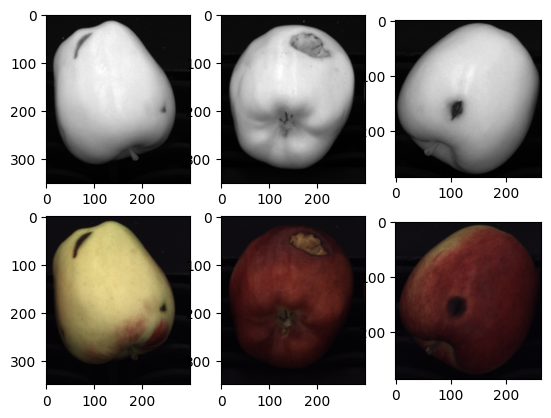

In [293]:
import cv2 
from matplotlib import pyplot as plt
import numpy as np

imgs = []

for i in range (3):    
    img = cv2.imread(f"first task/C0_00000{i+1}.png", cv2.IMREAD_GRAYSCALE)
    imgs.append(img)
    img_color = cv2.imread(f"first task/C1_00000{i+1}.png")          
    img_color = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
    plt.subplot(2,3,i+1)
    plt.imshow(img, cmap = 'gray')
    plt.subplot(2,3,i+4)
    plt.imshow(img_color)
plt.show()

The goal of this task was to outline defects on NIR images of apples.
This task was splitted in two parts: firstly we had to make use of a binary mask in order to isolate the apple's shape, while for the second part we had to search for actual defects on the apple.
In order to compute the binarization, we needed to apply some transformation on the image. The pipeline we adopted to get a proper mask is the following:
- A gaussian filter to denoise the image
- An exponential strethching and a linear stretching to improve the contrast of the image
- Actual thresholding using Otsu's algorithm to dynamically select the threshold
- *A median filter to remove small noises (to change with a blob analysis)*
- A blob detection to find possible holes inside the mask which we fill applying a flood fill 

All of these operations are encapsulated within the function called *create_binary_mask*

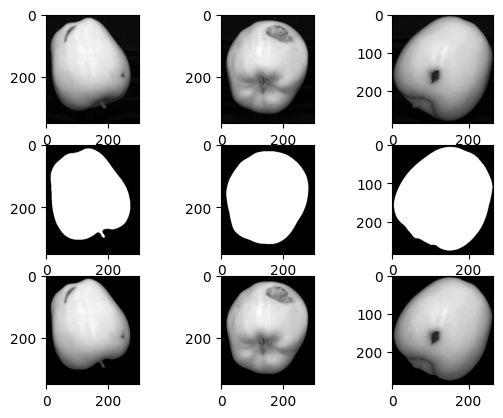

In [294]:
def linear_stretching_inner(img, max_value, min_value):
    img[img<min_value] = min_value
    img[img>max_value] = max_value
    transformed_img = 255./(max_value-min_value)*(img-min_value)
    return transformed_img

def linear_stretching(img, hist, min_perc, max_perc):
    max_value = find_percentile_value(hist, max_perc)
    min_value = find_percentile_value(hist, min_perc)
    res = linear_stretching_inner(img, max_value, min_value).astype(np.uint8) # light transformations for contrast
    return res

def exponential_operator(img, r):
    exp_img = ((img/255)**r) *255
    return exp_img

def find_percentile_value(hist, percentile):
    s = 0
    idx = 0
    total_pixel = np.sum(hist)
    while(s < total_pixel*percentile/100):
        s += hist[idx]
        idx += 1
    return idx

def create_binary_mask(img, r, min_perc, max_perc):
    img_blurred = cv2.GaussianBlur(np.copy(img), [0,0], 2, None, 2)         # gaussian filtering, sigma fine tuned
    gamma_img = exponential_operator(np.copy(img_blurred), r)
    hist,bins = np.histogram(gamma_img.flatten(),256,[0,256])
    transformed_img = linear_stretching(gamma_img,hist, min_perc, max_perc)

    thresh, thres_transformed_image = cv2.threshold(transformed_img, 127, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)    #thresholding on transformed image

    filled_img=cv2.medianBlur(np.copy(thres_transformed_image), 13)

    params = cv2.SimpleBlobDetector_Params()             # create parameters for blob detection
    params.filterByArea = False
    params.minRepeatability = 1
    params.minThreshold = 0
    params.maxThreshold = 20
    params.minDistBetweenBlobs = 4
    params.filterByCircularity = False 
    params.filterByInertia = False
    params.filterByConvexity = False
    detector = cv2.SimpleBlobDetector_create(params)
    keypoints = detector.detect(filled_img)             # find key points for blobs
    
    points = cv2.KeyPoint_convert(keypoints)
    for pt in points:                                   # flood fill eventual holes in the apple
        cv2.floodFill(filled_img, None, tuple(pt.astype(int)), 255)
    
    return filled_img


## Parameter declaration
binary_masks = []
min_perc = 10
max_perc = 70
r=0.25

for i in range (3):    
    binary_mask = create_binary_mask(np.copy(imgs[i]), r, min_perc, max_perc)
    img_masked = cv2.bitwise_and(binary_mask, imgs[i])
    binary_masks.append(binary_mask)
    
    plt.subplot(3,3,i+1)
    plt.imshow(imgs[i], cmap = 'gray')
    plt.subplot(3,3,i+4)
    plt.imshow(binary_mask, cmap = 'gray')
    plt.subplot(3,3,i+7)
    plt.imshow(img_masked, cmap = 'gray')
plt.show()

At this point, in order to trace out the defects, we performed an edge detection.
We blurred and stretched the image to denoise and increase the contrast before applying the Canny's detector on the masked image.
We proceded with a closing filter operation to fill some possible gaps on the contour, which turned advantageous in subsequent steps. 
Eventually we merged the images drawing the edges on the green channel. 

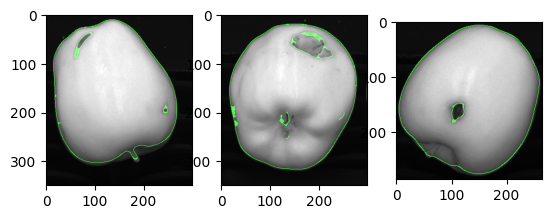

In [295]:
## parameter declaration
edges_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7))
canny_threshold_high = 120
canny_threshold_low = 10
edges = []

for i in range (3): 
    img_blurred = cv2.GaussianBlur(np.copy(imgs[i]), [0,0], 2.05, None, 2.05)
    hist,bins = np.histogram(img_blurred.flatten(),256,[0,256])
    linear_stretched_img = linear_stretching(np.copy(img_blurred),hist, min_perc, max_perc)
    img_masked = cv2.bitwise_and(binary_masks[i], linear_stretched_img.astype(np.uint8))

    edge = cv2.Canny(img_masked, canny_threshold_low, canny_threshold_high)
    closed_edge = cv2.morphologyEx(edge, cv2.MORPH_CLOSE, edges_kernel)   # closing to improve borders
    edges.append(closed_edge)
    
    img_edged = cv2.bitwise_or(imgs[i], closed_edge)
    img = cv2.merge([imgs[i], img_edged, imgs[i]])
    plt.subplot(1,3,i+1)
    plt.imshow(img, cmap = 'gray')
plt.show()


As we can see from the above images, we have many spurious edges. 
In order to Isolate the defects on the fruit, we only kept the closed contours.
Finally we filtered by size to delete the unnecessary fruit contour and only keep those around the defects.

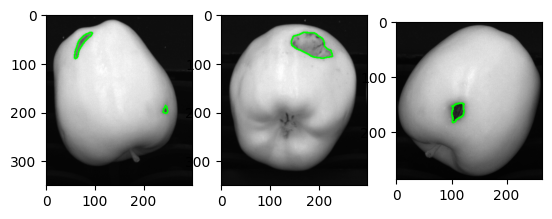

In [296]:
for i in range (3): 
    contours, hierarchy = cv2.findContours(edges[i], cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    img = cv2.merge([imgs[i], imgs[i], imgs[i]])
    for k in range(len(contours)):
        opened =  hierarchy[0][k][2]<0
        if (not opened) and cv2.contourArea(contours[k])<20000:
            cv2.drawContours(img, contours, k, (0,255,0), 2)
            
    plt.subplot(1,3,i+1)
    plt.imshow(img)
plt.show()

### Task 2: Fruit Russet Detection

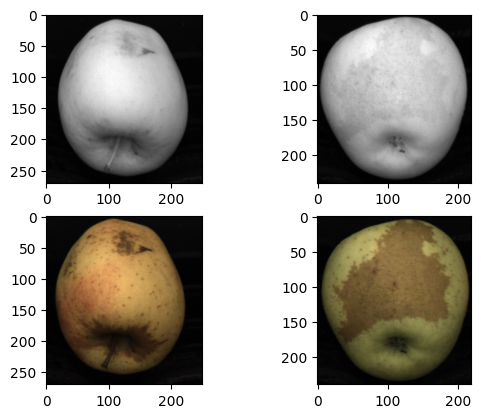

In [297]:
imgs = []

for i in range (2):    
    img = cv2.imread(f"second task/C0_00000{i+4}.png", cv2.IMREAD_GRAYSCALE)
    img_color = cv2.imread(f"second task/C1_00000{i+4}.png")        
    img_color = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
    imgs.append(img_color)  
    plt.subplot(2,2,i+1)
    plt.imshow(img, cmap = 'gray')
    plt.subplot(2,2,i+3)
    plt.imshow(img_color)
plt.show()

The goal of this task was to code an algorithm to identify russet on the given apple images. In order to accomplish this task we decided to implement a mahalanobis distance, since we verified that using a standard thresholding led to false positives, for example the stem was considered as part of russet.
A first attempt to exploit the needed statistics (mean and covariance) led to poor results because of reduced cardinality of the images. Hence we decided to compute the statistical properties on an artificial datased we created by taking a set of snaps from the original images, excluding the russet-affected regions, through a function we called *create_stats*, and with those we calculated the mahalanobis distance.
Another useful trick we applied was to change the samples and the images in LAB color space, but removing the L canal, in order to obtain images that were not too much affected by light changes.
We also applied a binary mask to the image in order to remove the background, and to calculate the mahalanobis distance.

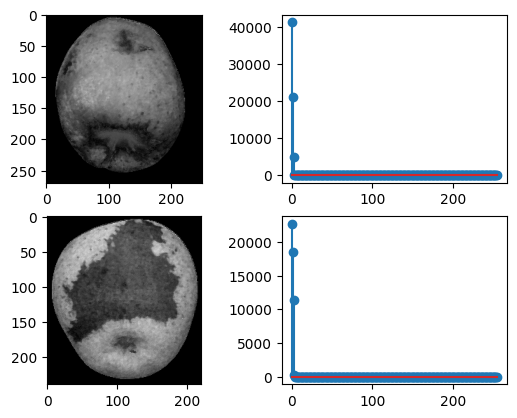

In [298]:
mahal_imgs = []

def create_stats():
    covariance_tot = np.zeros((2, 2), dtype="float64")
    mean_tot = np.zeros((1, 2), dtype="float64")
    for i in range(18):
        img = cv2.imread(f"second task/stats/{i+1}.png")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2LAB) [:,:,1:3]
        flat = img.reshape(-1,2)
        cov, mean = cv2.calcCovarMatrix(flat, None, cv2.COVAR_NORMAL | cv2.COVAR_ROWS | cv2.COVAR_SCALE)
        covariance_tot = np.add(covariance_tot, cov)
        mean_tot = np.add(mean_tot, mean)
    mean = mean_tot / 18
    iconv = np.linalg.inv(covariance_tot)
    return mean, iconv

for i in range (2):
    img_color_AB = cv2.cvtColor(np.copy(imgs[i]), cv2.COLOR_RGB2LAB)[:,:,1:3]
    img_bw = cv2.cvtColor(np.copy(imgs[i]), cv2.COLOR_RGB2GRAY)
    binary_mask = create_binary_mask(np.copy(img_bw), r, min_perc, max_perc)
    color_mask = cv2.merge([binary_mask, binary_mask])             # create color mask 
    img_masked = cv2.bitwise_and(color_mask, img_color_AB)

    mean, iconv = create_stats()

    img_flat = np.reshape(img_masked,(np.shape(imgs[i])[0]*np.shape(imgs[i])[1],2))
    diff = img_flat-mean
    diff[img_flat==0] = 0

    mahal = np.sqrt(np.multiply(np.dot(diff,iconv),diff).sum(-1))
    mahal_img = np.reshape(mahal, (np.shape(imgs[i])[0],np.shape(imgs[i])[1]))
    hist_mahal,bins_mahal = np.histogram(mahal_img.flatten(),256,[0,256])
    mahal_imgs.append(mahal_img)  

    plt.subplot(2,2,i*2+1)
    plt.imshow(mahal_img, cmap="gray")
    plt.subplot(2,2,i*2+2)
    plt.stem(hist_mahal)
plt.show()

After computing the Mahalanobis distance, we found it necessary to improve its thresholding by applying image processing. Following numerous attempts, we ultimately opted for a combination of normalization and the subsequent use of an exponential operator. The parameter for the exponential operator was meticulously fine-tuned.

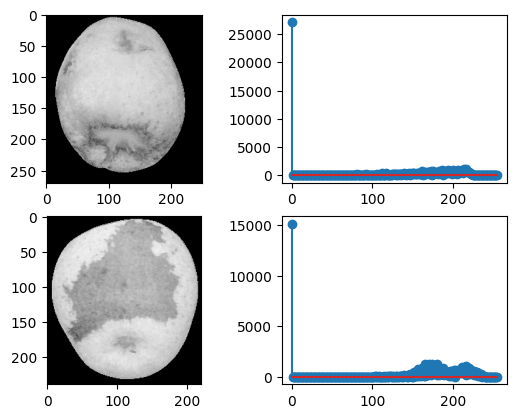

In [299]:
exp_imgs = []

for i in range (2): 
    mahal_image_norm = mahal_imgs[i] * 255 / np.max(mahal_imgs[i]) 
    exp_img = exponential_operator(mahal_image_norm, 0.3)
    exp_hist_mahal,bins_mahal = np.histogram(exp_img.flatten(),256,[0,256])
    exp_imgs.append(exp_img)

    plt.subplot(2,2,i*2+1)
    plt.imshow(exp_img, cmap="gray")
    plt.subplot(2,2,i*2+2)
    plt.stem(exp_hist_mahal)
plt.show()

Once we obtained the new histogram, we opted to implement Otsu thresholding since it offers a comprehensive solution for both images.

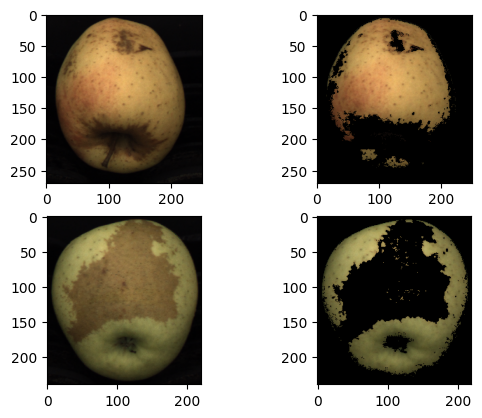

In [300]:
for i in range (2): 
    ret, null = cv2.threshold(exp_imgs[i].astype(np.uint8) [exp_imgs[i] != 0], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ret, thresholded_mahal_image = cv2.threshold(exp_imgs[i].astype(np.uint8), ret, 255, cv2.THRESH_BINARY)

    russet_mask = cv2.merge([thresholded_mahal_image, thresholded_mahal_image, thresholded_mahal_image])
    norusset_img = cv2.bitwise_and(russet_mask.astype(np.uint8), imgs[i])
    
    plt.subplot(2,2,i*2+1)
    plt.imshow(imgs[i])
    plt.subplot(2,2,i*2+2)
    plt.imshow(norusset_img)
plt.show()

The outcome is evidently lacking in accuracy, yet it provides an indication of the intended outcome. By potentially implementing further image processing or simply fine-tuning the parameters, it might be feasible to attain more favorable results. However, in our particular situation, even after numerous attempts, this represents the most successful outcome we have managed to achieve.

### Final Challenge: Kiwi Inspection

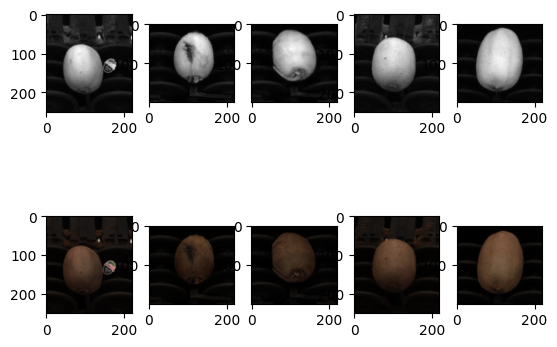

In [301]:
imgs = []

for i in range (5):    
    img = cv2.imread(f"final challenge/C0_00000{i+6}.png", cv2.IMREAD_GRAYSCALE)
    imgs.append(img)
    img_color = cv2.imread(f"final challenge/C1_00000{i+6}.png")          
    img_color = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
    plt.subplot(2,5,i+1)
    plt.imshow(img, cmap = 'gray')
    plt.subplot(2,5,i+6)
    plt.imshow(img_color)
plt.show()

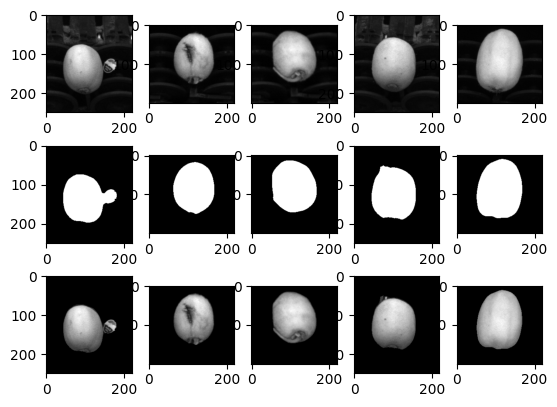

In [302]:
def create_binary_mask_2(img, r, min_perc, max_perc):
    img_blurred = cv2.GaussianBlur(np.copy(img), [0,0], 2, None, 2)     # gaussian filtering, sigma fine tuned
    gamma_img = exponential_operator(np.copy(img_blurred), r)
    hist,bins = np.histogram(img_blurred.flatten(),256,[0,256])

    transformed_img = linear_stretching(gamma_img, hist, min_perc, max_perc)

    thresh, thres_transformed_image = cv2.threshold(transformed_img, 127, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)    #thresholding on transformed image

    filled_img=cv2.medianBlur(np.copy(thres_transformed_image), 13)

    params = cv2.SimpleBlobDetector_Params()            # create parameters for blob detection
    params.filterByArea = False
    params.minArea = 100
    params.minRepeatability = 1
    params.minThreshold = 0
    params.maxThreshold = 255
    params.minDistBetweenBlobs = 4
    params.filterByCircularity = False 
    params.filterByInertia = False
    params.filterByConvexity = False
    params.filterByColor = True
    params.blobColor = 255
    detector = cv2.SimpleBlobDetector_create(params)
    keypoints = detector.detect(filled_img)             # find key points for blobs

    sizes = []
    for kp in keypoints:
        sizes.append(kp.size)
    idx = np.argmax(sizes)
    points = cv2.KeyPoint_convert(keypoints)
    points = np.delete(points, idx, 0)

    for pt in points:                                   # flood fill eventual holes in the apple
        cv2.floodFill(filled_img, None, tuple(pt.astype(int)), 0)

    return filled_img

binary_masks = []

for i in range (5):    
    ## Parameter declaration for light transformations
    min_perc=10
    max_perc=70
    r=1.3

    binary_mask = create_binary_mask_2(np.copy(imgs[i]), r, min_perc, max_perc)
    img_masked = cv2.bitwise_and(binary_mask, imgs[i])
    binary_masks.append(binary_mask)

    plt.subplot(3,5,i+1)
    plt.imshow(imgs[i], cmap = 'gray')
    plt.subplot(3,5,i+6)
    plt.imshow(binary_mask, cmap = 'gray')
    plt.subplot(3,5,i+11)
    plt.imshow(img_masked, cmap = 'gray')
plt.show()
    

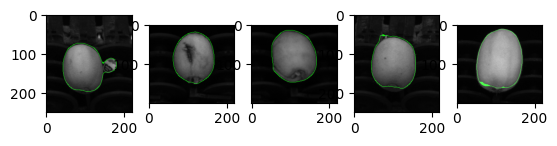

In [303]:
edges_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7))
canny_threshold_high = 120
canny_threshold_low = 10
edges = []

for i in range (5):

    img_blurred = cv2.GaussianBlur(np.copy(imgs[i]), [0,0], 2.05, None, 2.05)
    hist,bins = np.histogram(img_blurred.flatten(),256,[0,256])
    linear_stretched_img = linear_stretching(np.copy(img_blurred),hist, min_perc, max_perc)
    img_masked = cv2.bitwise_and(binary_masks[i], linear_stretched_img.astype(np.uint8))

    edge = cv2.Canny(img_masked, canny_threshold_low, canny_threshold_high)
    closed_edge = cv2.morphologyEx(edge, cv2.MORPH_CLOSE, edges_kernel)   # closing to improve borders
    edges.append(closed_edge)
    
    img_edged = cv2.bitwise_or(imgs[i], closed_edge)
    img = cv2.merge([imgs[i], img_edged, imgs[i]])
    plt.subplot(1,5,i+1)
    plt.imshow(img, cmap = 'gray')
plt.show()

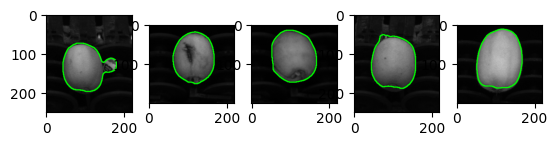

In [304]:
for i in range (5):
    contours, hierarchy = cv2.findContours(edges[i], cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    img = cv2.merge([imgs[i], imgs[i], imgs[i]])
    for k in range(len(contours)):
        opened =  hierarchy[0][k][2]<0
        if (not opened) and cv2.contourArea(contours[k])<20000:
            cv2.drawContours(img, contours, k, (0,255,0), 2)
    
    plt.subplot(1,5,i+1)
    plt.imshow(img)
plt.show()